# Optimal stopping: baseline numerical validation

## 1. Purpose

I check the analytical reference and inspect the retained numerical refinement experiment. This notebook introduces the continuous-yield model used to validate the initial numerical methods. The funded cash-event model and final conditional research questions are developed in [the replication notebook](27_conditional_research_replication.ipynb).

The inputs are stipulated mathematical fixtures. Simulated paths and model prices are not observed market data. Recomputing the analytical value checks the implementation; reading a retained refinement table does not repeat that experiment.

Methods and attribution are recorded in the [source register](../SOURCES.md), [theory](../theory.md) and [baseline findings](../results/baseline/findings.md). Install the repository and its notebook dependencies before running.

In [1]:
from pathlib import Path
import json

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
import csv
import math
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from qf_research.optimal_stopping.analytical import black_scholes
from qf_research.optimal_stopping.contracts import Market, Option

project = ROOT / "projects/01_optimal_stopping"
config = json.loads((project / "configs/benchmark.json").read_text())
manifest = json.loads((project / "results/baseline/manifest.json").read_text())
print(config["purpose"])
print(config["input_origin"])
print("Recorded seed:", config["seed"])


numerical_validation_only
Analytically specified test fixture; not observed market data
Recorded seed: 20260914


## 2. Analytical reference

The saved put contract has constant coefficients. Recomputing the analytical value provides a deterministic baseline before interpreting the discretised early-exercise methods. This check uses no new random samples.

In [2]:
market = Market(**config["market"])
option = Option(**config["option"])
value = black_scholes(market, option)
reference = manifest["references"]["european_analytical"]
assert math.isclose(value, reference, rel_tol=1e-12, abs_tol=1e-12)
print(f"Recomputed European value: {value:.10f}")
print(f"Saved European reference: {reference:.10f}")
print("Agreement within the stated numerical tolerance.")


Recomputed European value: 5.5735260223
Saved European reference: 5.5735260223
Agreement within the stated numerical tolerance.


## 3. Retained refinement experiment

These values come from the recorded benchmark run. The next cell reads its output, rather than rerunning the whole experiment. European errors are measured against the analytical solution. Bermudan differences use a fine PDE reference, which is itself a numerical approximation.

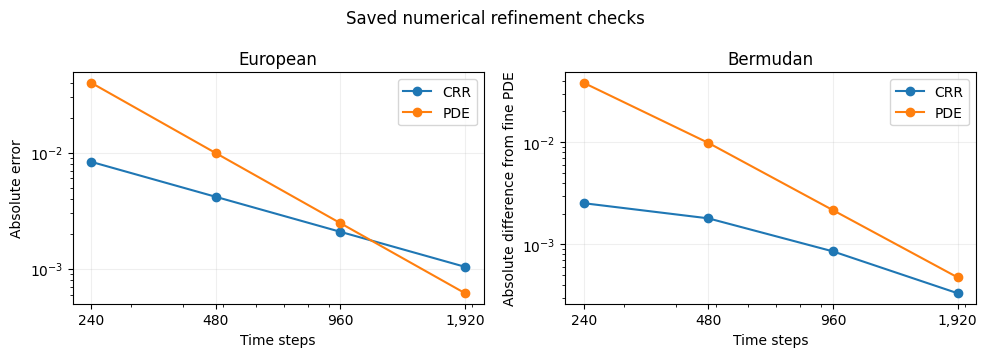

In [3]:
with (project / "results/baseline/grid_convergence.csv").open(newline="") as stream:
    rows = list(csv.DictReader(stream))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, contract in zip(axes, ["European", "Bermudan"]):
    for method in ["CRR", "PDE"]:
        selected = [r for r in rows if r["contract"] == contract and r["method"] == method]
        ax.loglog([int(r["time_steps"]) for r in selected],
                  [abs(float(r["error"])) for r in selected], marker="o", label=method)
    ax.set_title(contract)
    ax.set_xlabel("Time steps")
    time_counts = sorted({int(r["time_steps"]) for r in rows if r["contract"] == contract})
    ax.set_xticks(time_counts, labels=[f"{count:,}" for count in time_counts])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_ylabel("Absolute error" if contract == "European" else "Absolute difference from fine PDE")
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle("Saved numerical refinement checks")
fig.tight_layout()
plt.show()


## 4. Interpretation

Agreement across numerical methods supports numerical consistency; it does not certify an upper or lower bound on the optimal value. The PDE sequence changes both time and space resolution, so the plotted slope does not isolate an order of convergence in time. CRR space resolution is determined by its time grid.

The completed study concerns policy-loss measurement, training uncertainty and computational allocation within specified financial models. Its conclusions do not require interpreting these validation fixtures as a sample of traded options. The [replication notebook](27_conditional_research_replication.ipynb) executes the funded-model workflow and distinguishes its mathematical examples from the released research summaries. Independent historical market validation remains outside the completed evidential scope.